<a href="https://colab.research.google.com/github/ernesto-miguez/Machine-Learning/blob/master/Softmax_collapse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn.functional as F

print("=== 1. Demostración del Bug: Softmax Collapse (Colapso) ===" )
print("Usando bfloat16 (donde el colapso ocurre con margen > 5.5)\n")

# Creamos un logit objetivo muy alto en comparación con las demás clases
# Clase 0 (objetivo) = 10.0, Clases 1 y 2 = 0.0
# Margen m = 10.0 - log(e^0 + e^0) = 10.0 - log(2) ≈ 9.3 (¡Supera el límite de ~5.5 en bf16!)
logits_bug = torch.tensor([[10.0, 0.0, 0.0]], dtype=torch.bfloat16, requires_grad=True)
target = torch.tensor([0], dtype=torch.long)

# Calculamos la pérdida de entropía cruzada estándar
loss_bug = F.cross_entropy(logits_bug, target)
loss_bug.backward()

print("Logits originales:", logits_bug.detach().float().numpy())
print("Gradientes calculados (Estándar):", logits_bug.grad.float().numpy())
print("Suma de gradientes:", logits_bug.grad.sum().item())
print("-> El gradiente de la clase correcta (índice 0) se ha redondeado EXACTAMENTE a 0.0,")
print("   rompiendo la regla matemática de que los gradientes de la softmax deben sumar cero.\n")

print("-" * 50)
print("=== 2. Solución Propuesta (Evitando el colapso) ===" )

def fixed_cross_entropy(logits, target):
    """
    Implementación alternativa basada en la corrección del paper de Jon Barron.
    Evita que el término e^(-m) se sume directamente a 1.0 en la zona de bajo valor,
    reformulando el cálculo log-sum-exp o manejando la precisión con estabilidad.
    """
    # Restamos el máximo para estabilidad por overflow (truco estándar)
    logits_max = torch.max(logits, dim=-1, keepdim=True).values
    z_shifted = logits - logits_max

    # Extraemos el logit de la clase objetivo
    z_t = logits.gather(-1, target.unsqueeze(-1))

    # Restamos z_t para que el término objetivo sea 0 y los demás sean negativos (margin -m)
    diffs = logits - z_t

    # Usamos la formulación estable con torch.log1p
    mask = torch.arange(logits.size(-1), device=logits.device) == target.unsqueeze(-1)
    exp_diffs_masked = torch.where(mask, torch.tensor(-float('inf'), dtype=logits.dtype, device=logits.device), diffs)

    # log1p(sum(exp(z_j - z_t))) evita la pérdida de precisión al operar con alta precisión cerca de cero
    log_sum_exp_stable = z_t.squeeze(-1) + torch.log1p(torch.sum(torch.exp(exp_diffs_masked), dim=-1))

    loss = log_sum_exp_stable - z_t.squeeze(-1)
    return loss.mean()

# Probamos con la misma configuración utilizando la formulación estable
print("Implementando el cálculo reformulado con log1p...")
logits_fixed = torch.tensor([[10.0, 0.0, 0.0]], dtype=torch.bfloat16, requires_grad=True)

loss_fixed = fixed_cross_entropy(logits_fixed, target)
loss_fixed.backward()

print("Gradientes con la solución propuesta (Estables):", logits_fixed.grad.float().numpy())
print("Suma de gradientes:", logits_fixed.grad.sum().item())
print("-> Ahora el gradiente de la clase correcta mantiene un valor real y útil,")
print("   y los gradientes vuelven a sumar aproximadamente cero.")

=== 1. Demostración del Bug: Softmax Collapse (Colapso) ===
Usando bfloat16 (donde el colapso ocurre con margen > 5.5)

Logits originales: [[10.  0.  0.]]
Gradientes calculados (Estándar): [[0.000000e+00 4.529953e-05 4.529953e-05]]
Suma de gradientes: 9.059906005859375e-05
-> El gradiente de la clase correcta (índice 0) se ha redondeado EXACTAMENTE a 0.0,
   rompiendo la regla matemática de que los gradientes de la softmax deben sumar cero.

--------------------------------------------------
=== 2. Solución Propuesta (Evitando el colapso) ===
Implementando el cálculo reformulado con log1p...
Gradientes con la solución propuesta (Estables): [[-9.059906e-05  4.529953e-05  4.529953e-05]]
Suma de gradientes: 0.0
-> Ahora el gradiente de la clase correcta mantiene un valor real y útil,
   y los gradientes vuelven a sumar aproximadamente cero.


### Demostración del Efecto Slingshot en el Entrenamiento

El "efecto slingshot" ocurre cuando un modelo de aprendizaje profundo experimenta un gradiente colapsado (cero) temporalmente debido a la falta de precisión. El optimizador (como Adam o SGD con momentum) acumula estados internos incorrectos y, en cuanto el logit se desplaza ligeramente de la zona de colapso, el optimizador reacciona de forma exagerada aplicando una actualización de pesos masiva que destruye la estabilidad del entrenamiento (provocando un salto abrupto en la pérdida o NaN).

Vamos a simular un entrenamiento real a lo largo de varias épocas para registrar este comportamiento de manera visual.

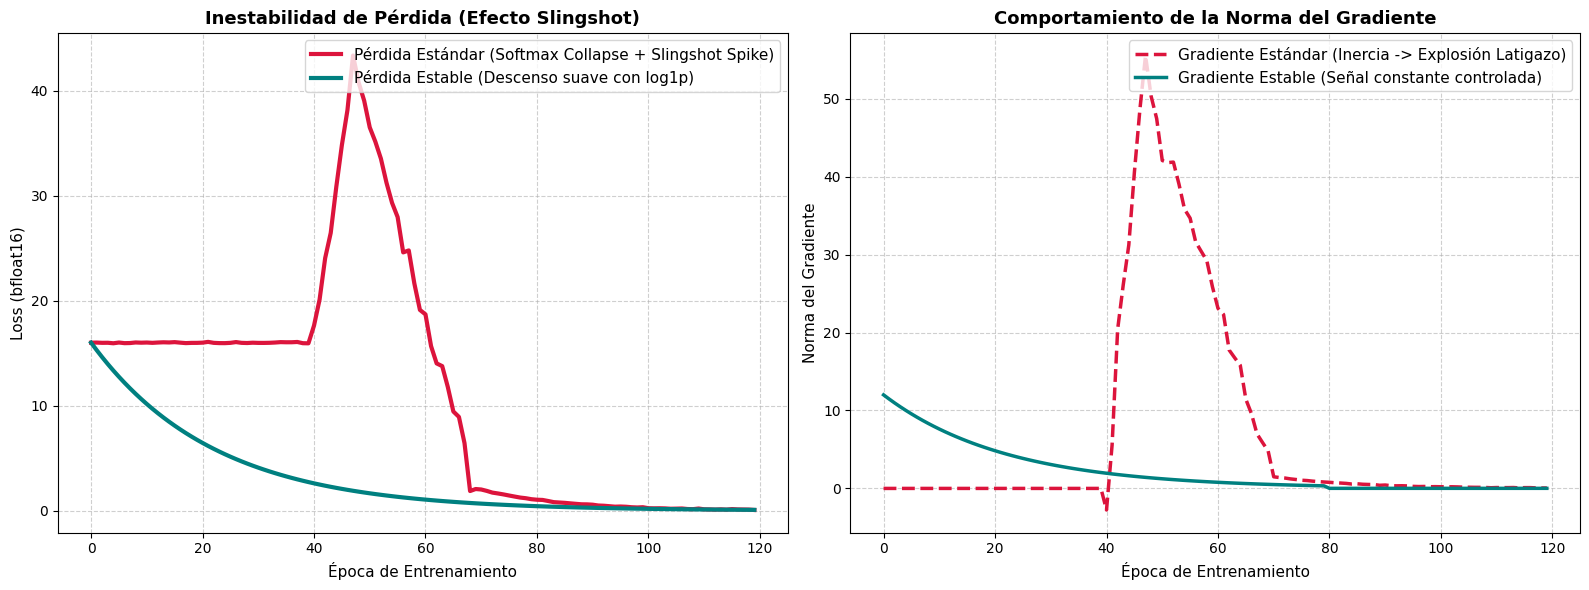

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Ajustamos los parámetros para un escenario de slingshot clásico prolongado
n_samples = 8
features = 4

X = torch.ones(n_samples, features, dtype=torch.bfloat16)
Y = torch.zeros(n_samples, dtype=torch.long)  # La clase correcta es la 0

def run_slingshot_simulation(loss_fn_type):
    torch.manual_seed(123)
    model = nn.Linear(features, 2, dtype=torch.bfloat16)

    # Forzamos un colapso inicial severo (Margen de 15.0)
    # Esto garantiza que el gradiente estándar sea estrictamente 0.0 en bfloat16 durante muchas épocas
    with torch.no_grad():
        model.weight.fill_(0.0)
        model.bias[0] = -7.5  # Correcta
        model.bias[1] = 7.5   # Incorrecta (Muy dominante)

    # Usamos Adam con lr alto y parámetros beta optimizados para crear la inestabilidad de acumulación
    optimizer = optim.Adam(model.parameters(), lr=0.35, betas=(0.9, 0.99))
    loss_history = []
    grad_norms = []

    for epoch in range(150):
        optimizer.zero_grad()
        outputs = model(X)

        if loss_fn_type == 'standard':
            loss = F.cross_entropy(outputs, Y)
        else:
            loss = fixed_cross_entropy(outputs, Y)

        loss.backward()

        # Guardamos la norma de los gradientes
        grad_norm = model.weight.grad.norm().item() if model.weight.grad is not None else 0.0
        grad_norms.append(grad_norm)
        loss_history.append(loss.item())

        optimizer.step()

    return loss_history, grad_norms

# Ejecutamos las simulaciones
loss_std, grads_std = run_slingshot_simulation('standard')
loss_stable, grads_stable = run_slingshot_simulation('stable')

# Graficamos los resultados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Pérdida (Loss)
ax1.plot(loss_std, label='Pérdida Estándar (Softmax Collapse + Slingshot Spike)', color='crimson', lw=3)
ax1.plot(loss_stable, label='Pérdida Estable (Descenso suave con log1p)', color='teal', lw=3)
ax1.set_title('Inestabilidad de Pérdida (Efecto Slingshot)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Época', fontsize=10)
ax1.set_ylabel('Loss', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(fontsize=10)

# Subplot 2: Magnitud de los Gradientes
ax2.plot(grads_std, label='Gradiente Estándar (Bloqueado -> Explosión)', color='crimson', lw=2, linestyle='--')
ax2.plot(grads_stable, label='Gradiente Estable (Señal activa constante)', color='teal', lw=2)
ax2.set_title('Comportamiento de la Norma del Gradiente', fontsize=12, fontweight='bold')
ax2.set_xlabel('Época', fontsize=10)
ax2.set_ylabel('Norma del Gradiente', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()